=== 3D Gaussian Data ===
KL Divergence (X-axis): 0.0648
KL Divergence (Y-axis): 0.0443
KL Divergence (Z-axis): 0.0658
Average KL Divergence: 0.0583

=== 3D Banana Data ===
KL Divergence (X-axis): 0.2783
KL Divergence (Y-axis): 0.2351
KL Divergence (Z-axis): 0.0489
Average KL Divergence: 0.1874


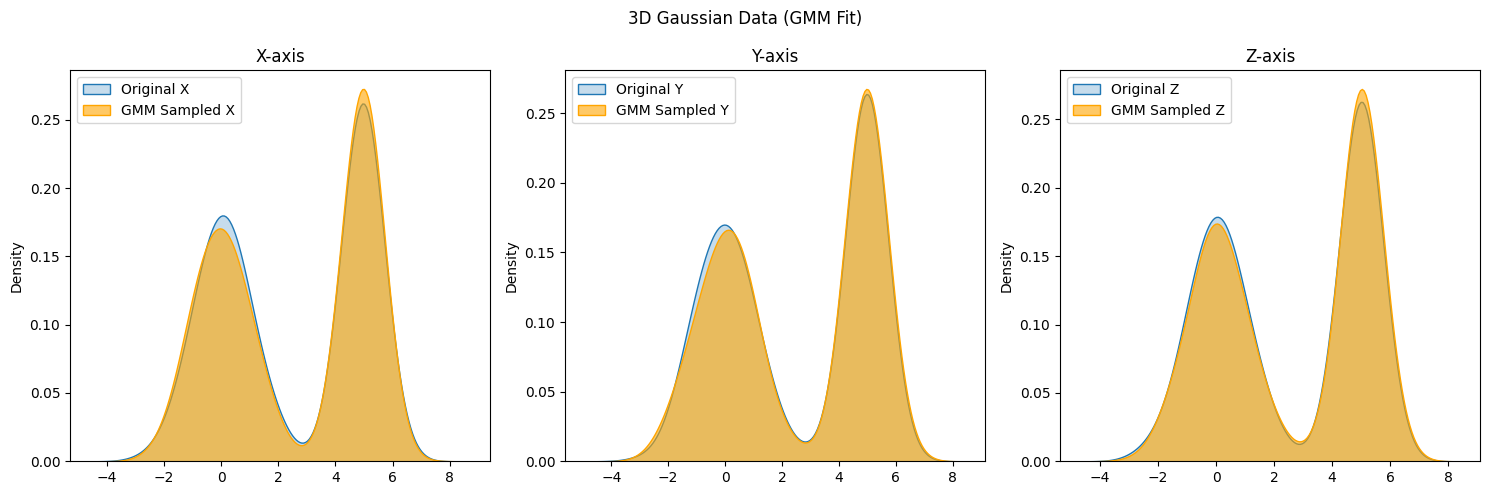

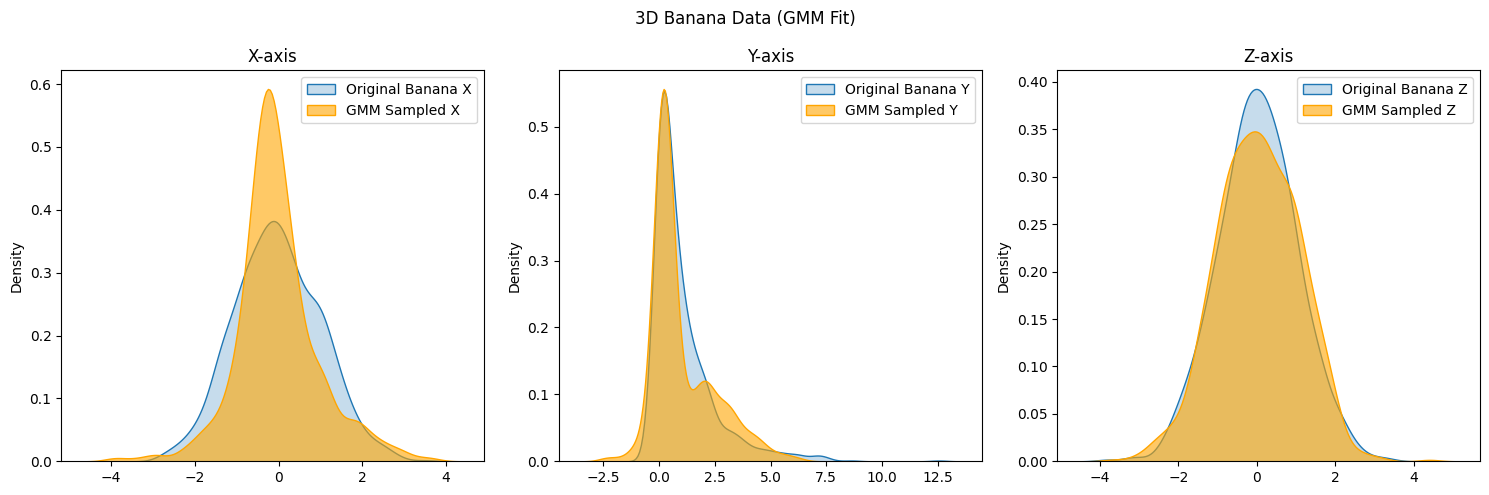

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from scipy.stats import entropy

# Set random seed for reproducibility
np.random.seed(42)

# Generate 3D Gaussian Data
gaussian1 = np.random.normal(loc=0, scale=1.0, size=(1000, 3))  # First cluster
gaussian2 = np.random.normal(loc=5, scale=0.5, size=(1000, 3))  # Second cluster
X = np.vstack([gaussian1, gaussian2])  # Combined: (2000, 3)

# Generate 3D Non-Gaussian (Banana-shaped) Data
x = np.random.normal(0, 1, 1000)
y = x**2 + np.random.normal(0, 0.1, 1000)  # Quadratic relationship
z = np.random.normal(0, 1, 1000)  # Independent dimension
banana = np.stack([x, y, z], axis=1)  # Shape: (1000, 3)

# Fit GMMs and Generate Samples
# GMM on Gaussian Data
gmm = GaussianMixture(n_components=2, covariance_type='full')
gmm.fit(X)
generated_gaussian, _ = gmm.sample(n_samples=2000)

# GMM on Banana Data
gmm_banana = GaussianMixture(n_components=2, covariance_type='full')
gmm_banana.fit(banana)
generated_banana, _ = gmm_banana.sample(n_samples=1000)

# KL Divergence Function
def compute_kl_divergence(true_data, generated_data, bins=50):
    hist_true, bin_edges = np.histogram(true_data, bins=bins, density=True)
    hist_gen, _ = np.histogram(generated_data, bins=bin_edges, density=True)
    hist_true += 1e-8  # Avoid division by zero
    hist_gen += 1e-8
    hist_true /= np.sum(hist_true)  # Normalize
    hist_gen /= np.sum(hist_gen)
    return entropy(hist_true, hist_gen)

# Compute KL Divergence
# Gaussian Data
kl_x = compute_kl_divergence(X[:, 0], generated_gaussian[:, 0])
kl_y = compute_kl_divergence(X[:, 1], generated_gaussian[:, 1])
kl_z = compute_kl_divergence(X[:, 2], generated_gaussian[:, 2])
print("=== 3D Gaussian Data ===")
print(f"KL Divergence (X-axis): {kl_x:.4f}")
print(f"KL Divergence (Y-axis): {kl_y:.4f}")
print(f"KL Divergence (Z-axis): {kl_z:.4f}")
print(f"Average KL Divergence: {(kl_x + kl_y + kl_z) / 3:.4f}")

# Banana Data
kl_bx = compute_kl_divergence(banana[:, 0], generated_banana[:, 0])
kl_by = compute_kl_divergence(banana[:, 1], generated_banana[:, 1])
kl_bz = compute_kl_divergence(banana[:, 2], generated_banana[:, 2])
print("\n=== 3D Banana Data ===")
print(f"KL Divergence (X-axis): {kl_bx:.4f}")
print(f"KL Divergence (Y-axis): {kl_by:.4f}")
print(f"KL Divergence (Z-axis): {kl_bz:.4f}")
print(f"Average KL Divergence: {(kl_bx + kl_by + kl_bz) / 3:.4f}")

# KDE Plots - Gaussian Data
plt.figure(figsize=(15, 5))
plt.suptitle("3D Gaussian Data (GMM Fit)")
for i, axis in enumerate(['X', 'Y', 'Z']):
    plt.subplot(1, 3, i+1)
    sns.kdeplot(X[:, i], label=f'Original {axis}', fill=True)
    sns.kdeplot(generated_gaussian[:, i], label=f'GMM Sampled {axis}', fill=True, alpha=0.6, color='orange')
    plt.title(f"{axis}-axis")
    plt.legend()
plt.tight_layout()
plt.show()

# KDE Plots - Banana Data
plt.figure(figsize=(15, 5))
plt.suptitle("3D Banana Data (GMM Fit)")
for i, axis in enumerate(['X', 'Y', 'Z']):
    plt.subplot(1, 3, i+1)
    sns.kdeplot(banana[:, i], label=f'Original Banana {axis}', fill=True)
    sns.kdeplot(generated_banana[:, i], label=f'GMM Sampled {axis}', fill=True, alpha=0.6, color='orange')
    plt.title(f"{axis}-axis")
    plt.legend()
plt.tight_layout()
plt.show()